# Handwritten Digit Recognition Using MNIST Dataset with TensorFlow and Keras

**Academic project | 30-mark assignment**

This notebook builds, trains, and evaluates a convolutional neural network (CNN) for recognizing handwritten digits (0–9). Run the cells from top to bottom in Google Colab or Jupyter. Training results are printed from the actual run; no result is assumed in advance.

## Part 1: Data Preparation and Preprocessing (10 Marks)

We load the standard MNIST training and test sets, inspect and visualize examples, scale the pixels, and create a validation set from the original training data. The test set stays separate until final evaluation.

In [ ]:
# If a required package is missing in your environment, uncomment and run this line.
# %pip install -r requirements.txt
# In Google Colab, you can instead use: %pip install tensorflow numpy matplotlib scikit-learn seaborn pandas

In [21]:
!pip install tensorflow[and-cuda]


^C


INFO: pip is looking at multiple versions of tensorflow[and-cuda] to determine which version is compatible with other requirements. This could take a while.
INFO: pip is still looking at multiple versions of tensorflow[and-cuda] to determine which version is compatible with other requirements. This could take a while.
INFO: This is taking longer than usual. You might need to provide the dependency resolver with stricter constraints to reduce runtime. See https://pip.pypa.io/warnings/backtracking for guidance. If you want to abort this run, press Ctrl + C.
INFO: pip is looking at multiple versions of grpcio to determine which version is compatible with other requirements. This could take a while.
INFO: pip is still looking at multiple versions of grpcio to determine which version is compatible with other requirements. This could take a while.
   ---------------------------------------- 0.0/276.6 MB ? eta -:--:--
   ---------------------------------------- 0.1/276.6 MB 2.8 MB/s eta 0:01:

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
langchain-cor

In [20]:
import os
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

# SEED = 42
# os.environ["PYTHONHASHSEED"] = str(SEED)
# random.seed(SEED)
# np.random.seed(SEED)
# tf.keras.utils.set_random_seed(SEED)

print(f"TensorFlow version: {tf.__version__}")
print("GPUs:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.20.0
GPUs: []


### Load and inspect MNIST

Keras supplies MNIST as 60,000 training images and 10,000 official test images. Each image is 28 by 28 grayscale pixels and each label is an integer from 0 to 9. We print the array shapes and sample counts so the data dimensions are explicit.

In [15]:
(x_train_original, y_train_original), (x_test_raw, y_test) = tf.keras.datasets.mnist.load_data()

print(f"Original training images: {x_train_original.shape}")
print(f"Original training labels: {y_train_original.shape}")
print(f"Official test images:      {x_test_raw.shape}")
print(f"Official test labels:      {y_test.shape}")
print(f"Training samples: {len(x_train_original):,}")
print(f"Test samples:     {len(x_test_raw):,}")
print(f"Image dimensions: {x_train_original.shape[1]} x {x_train_original.shape[2]} grayscale pixels")
print(f"Number of classes: {len(np.unique(y_train_original))}")

Original training images: (60000, 28, 28)
Original training labels: (60000,)
Official test images:      (10000, 28, 28)
Official test labels:      (10000,)
Training samples: 60,000
Test samples:     10,000
Image dimensions: 28 x 28 grayscale pixels
Number of classes: 10


### Visualize sample digits

Each subplot shows a training image and its integer class label. Looking at real examples helps verify that the labels and image orientation make sense before modeling.

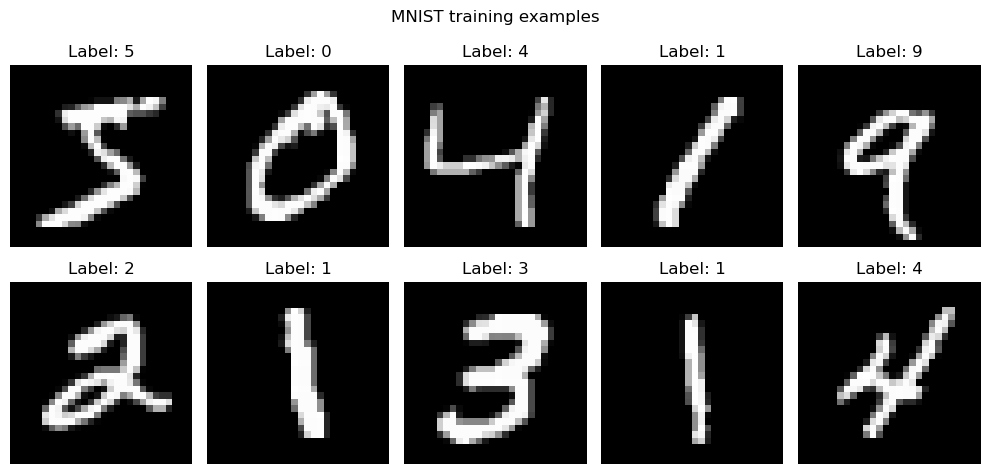

In [16]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for image, label, axis in zip(x_train_original[:10], y_train_original[:10], axes.flat):
    axis.imshow(image, cmap="gray")
    axis.set_title(f"Label: {label}")
    axis.axis("off")
fig.suptitle("MNIST training examples")
plt.tight_layout()
plt.show()

### Normalize, reshape, and split

Pixel values originally range from 0 to 255. Dividing by 255 converts them to 0–1, a scale that generally makes neural-network optimization more stable. A CNN expects an explicit channel dimension, so we reshape each image from 28×28 to 28×28×1. We reserve 10,000 of the official 60,000 training examples for validation using a stratified split, preserving class proportions. This leaves 50,000 training + 10,000 validation + 10,000 official test examples: a 70/15/15 split of all 70,000 examples. The official test set is not used for fitting, validation, or model selection. Labels remain integers for sparse categorical cross-entropy; no one-hot conversion is needed.

In [17]:
# Convert to float32 and normalize pixel intensities to [0, 1].
x_train_all = x_train_original.astype("float32") / 255.0
x_test = x_test_raw.astype("float32") / 255.0

# Add the single grayscale channel expected by Conv2D.
x_train_all = x_train_all[..., np.newaxis]
x_test = x_test[..., np.newaxis]

x_train, x_validation, y_train, y_validation = train_test_split(
    x_train_all,
    y_train_original,
    test_size=1 / 6,
    random_state=SEED,
    stratify=y_train_original,
)

print(f"Training set:   {x_train.shape}, labels {y_train.shape}")
print(f"Validation set: {x_validation.shape}, labels {y_validation.shape}")
print(f"Test set:       {x_test.shape}, labels {y_test.shape}")
print(f"Normalized pixel range: {x_train.min():.1f} to {x_train.max():.1f}")
print("Split counts (train/validation/test):", len(x_train), len(x_validation), len(x_test))

Training set:   (50000, 28, 28, 1), labels (50000,)
Validation set: (10000, 28, 28, 1), labels (10000,)
Test set:       (10000, 28, 28, 1), labels (10000,)
Normalized pixel range: 0.0 to 1.0
Split counts (train/validation/test): 50000 10000 10000


### Data augmentation

Small random rotations and translations create plausible variations of the training digits. These Keras preprocessing layers are placed inside the model, so they are applied only during training and are inactive during validation and prediction. This avoids modifying validation or test examples. Augmentation is intentionally mild because large transformations could change a digit's identity.

## Part 2: Model Creation and Training (10 Marks)

We construct a CNN that learns local image features, compile it with the required optimizer and integer-label loss, and train with validation monitoring. Early stopping limits unnecessary training, while checkpointing saves the best validation-loss model.

In [18]:
data_augmentation = tf.keras.Sequential(
    [
        tf.keras.layers.RandomRotation(factor=0.05, seed=SEED),
        tf.keras.layers.RandomTranslation(height_factor=0.05, width_factor=0.05, seed=SEED),
    ],
    name="training_augmentation",
)

model = tf.keras.Sequential(
    [
        tf.keras.Input(shape=(28, 28, 1)),
        data_augmentation,
        tf.keras.layers.Conv2D(32, kernel_size=3, activation="relu", padding="same"),
        tf.keras.layers.MaxPooling2D(pool_size=2),
        tf.keras.layers.Conv2D(64, kernel_size=3, activation="relu", padding="same"),
        tf.keras.layers.MaxPooling2D(pool_size=2),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dropout(0.30),
        tf.keras.layers.Dense(10, activation="softmax"),
    ],
    name="mnist_digit_cnn",
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

Model: "mnist_digit_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ training_augmentation           │ (None, 28, 28, 1)      │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

### Architecture and training choices

- **Convolution + ReLU:** filters learn visual patterns such as strokes and edges; ReLU keeps positive responses and provides a simple nonlinearity.
- **Max pooling:** reduces spatial size while retaining strong local features. Two convolution/pooling blocks learn increasingly useful patterns.
- **Flatten + Dense:** converts feature maps into a vector and combines learned features to classify a digit. The final 10-neuron softmax produces a probability distribution over digits 0–9.
- **Dropout (0.30):** randomly disables some hidden activations during training to reduce over-reliance on particular features.
- **Adam:** an adaptive gradient-based optimizer that adjusts update sizes during learning. Sparse categorical cross-entropy compares the predicted class probabilities with integer labels. Accuracy is the fraction of correct predictions.
- **Hyperparameters:** batch size 128 balances update frequency and efficiency; training is capped at 20 epochs. Early stopping watches validation loss with patience 3 and restores the best weights. The checkpoint file stores the best full model.

In [19]:
checkpoint_path = "best_mnist_cnn.keras"
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True, verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=checkpoint_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1,
    ),
]

history = model.fit(
    x_train,
    y_train,
    validation_data=(x_validation, y_validation),
    epochs=20,
    batch_size=128,
    callbacks=callbacks,
    verbose=1,
)

print(f"Best model saved to: {checkpoint_path}")
print(f"Epochs completed: {len(history.history['loss'])}")

Epoch 1/20
388/391 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.7760 - loss: 0.7244
Epoch 1: val_loss improved from None to 0.07613, saving model to best_mnist_cnn.keras
391/391 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - accuracy: 0.8837 - loss: 0.3758 - val_accuracy: 0.9766 - val_loss: 0.0761
Epoch 2/20
389/391 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9532 - loss: 0.1503
Epoch 2: val_loss improved from 0.07613 to 0.05425, saving model to best_mnist_cnn.keras
391/391 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.9581 - loss: 0.1382 - val_accuracy: 0.9838 - val_loss: 0.0543
Epoch 3/20
 12/391 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.9625 - loss: 0.1302

KeyboardInterrupt: 

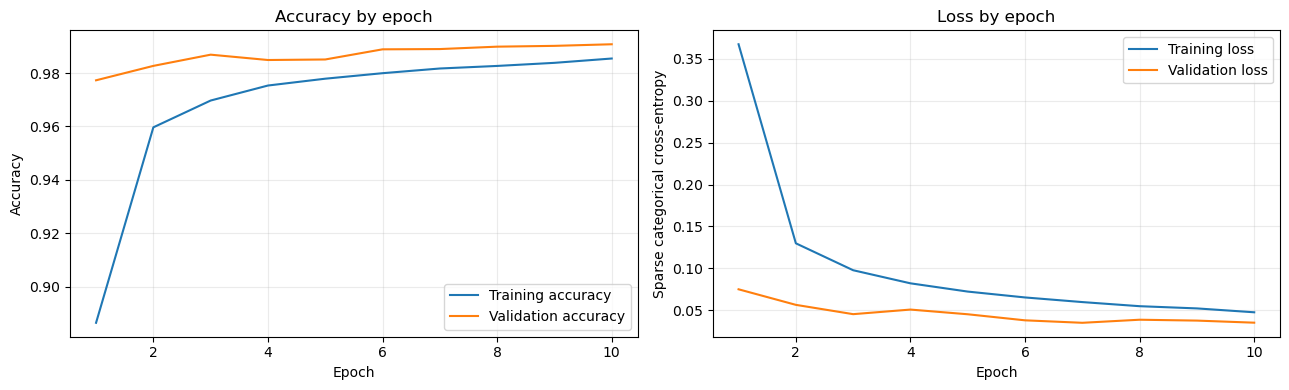

In [7]:
epochs_ran = range(1, len(history.history["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(epochs_ran, history.history["accuracy"], label="Training accuracy")
axes[0].plot(epochs_ran, history.history["val_accuracy"], label="Validation accuracy")
axes[0].set_title("Accuracy by epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(epochs_ran, history.history["loss"], label="Training loss")
axes[1].plot(epochs_ran, history.history["val_loss"], label="Validation loss")
axes[1].set_title("Loss by epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Sparse categorical cross-entropy")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

## Part 3: Evaluation, Testing, and Reporting (10 Marks)

Only now do we use the independent official test set. It is evaluated once after training and model selection. The following cells print measured metrics, examine class-level errors, and visualize predictions.

In [8]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
test_probabilities = model.predict(x_test, batch_size=256, verbose=0)
y_pred = np.argmax(test_probabilities, axis=1)

print(f"Test loss:     {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f} ({test_accuracy:.2%})")

Test loss:     0.0218
Test accuracy: 0.9917 (99.17%)


Classification report (one row per digit):
              precision    recall  f1-score   support

           0     0.9959    0.9959    0.9959       980
           1     0.9964    0.9850    0.9907      1135
           2     0.9894    0.9981    0.9937      1032
           3     0.9901    0.9941    0.9921      1010
           4     0.9919    0.9939    0.9929       982
           5     0.9944    0.9910    0.9927       892
           6     0.9916    0.9906    0.9911       958
           7     0.9932    0.9874    0.9902      1028
           8     0.9838    0.9949    0.9893       974
           9     0.9901    0.9871    0.9886      1009

    accuracy                         0.9917     10000
   macro avg     0.9917    0.9918    0.9917     10000
weighted avg     0.9917    0.9917    0.9917     10000



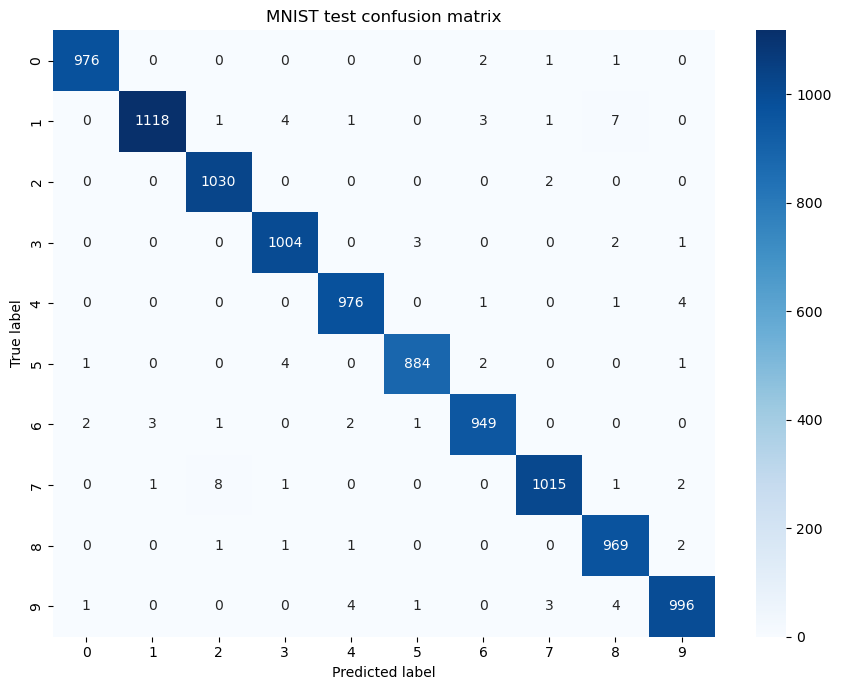

In [9]:
digit_labels = list(range(10))
print("Classification report (one row per digit):")
print(
    classification_report(
        y_test,
        y_pred,
        labels=digit_labels,
        target_names=[str(digit) for digit in digit_labels],
        digits=4,
        zero_division=0,
    )
)

confusion = confusion_matrix(y_test, y_pred, labels=digit_labels)
plt.figure(figsize=(9, 7))
sns.heatmap(
    confusion,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=digit_labels,
    yticklabels=digit_labels,
    cbar=True,
)
plt.title("MNIST test confusion matrix")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.tight_layout()
plt.show()

In [10]:
report = classification_report(
    y_test, y_pred, labels=digit_labels, output_dict=True, zero_division=0
)
results_table = pd.DataFrame(
    [
        {
            "Test accuracy": test_accuracy,
            "Macro precision": report["macro avg"]["precision"],
            "Macro recall": report["macro avg"]["recall"],
            "Macro F1-score": report["macro avg"]["f1-score"],
            "Weighted precision": report["weighted avg"]["precision"],
            "Weighted recall": report["weighted avg"]["recall"],
            "Weighted F1-score": report["weighted avg"]["f1-score"],
        }
    ]
)
print("Measured test-set results (computed from this run):")
display(results_table.round(4))

Measured test-set results (computed from this run):


,Test accuracy,Macro precision,Macro recall,Macro F1-score,Weighted precision,Weighted recall,Weighted F1-score
0,0.9917,0.9917,0.9918,0.9917,0.9917,0.9917,0.9917


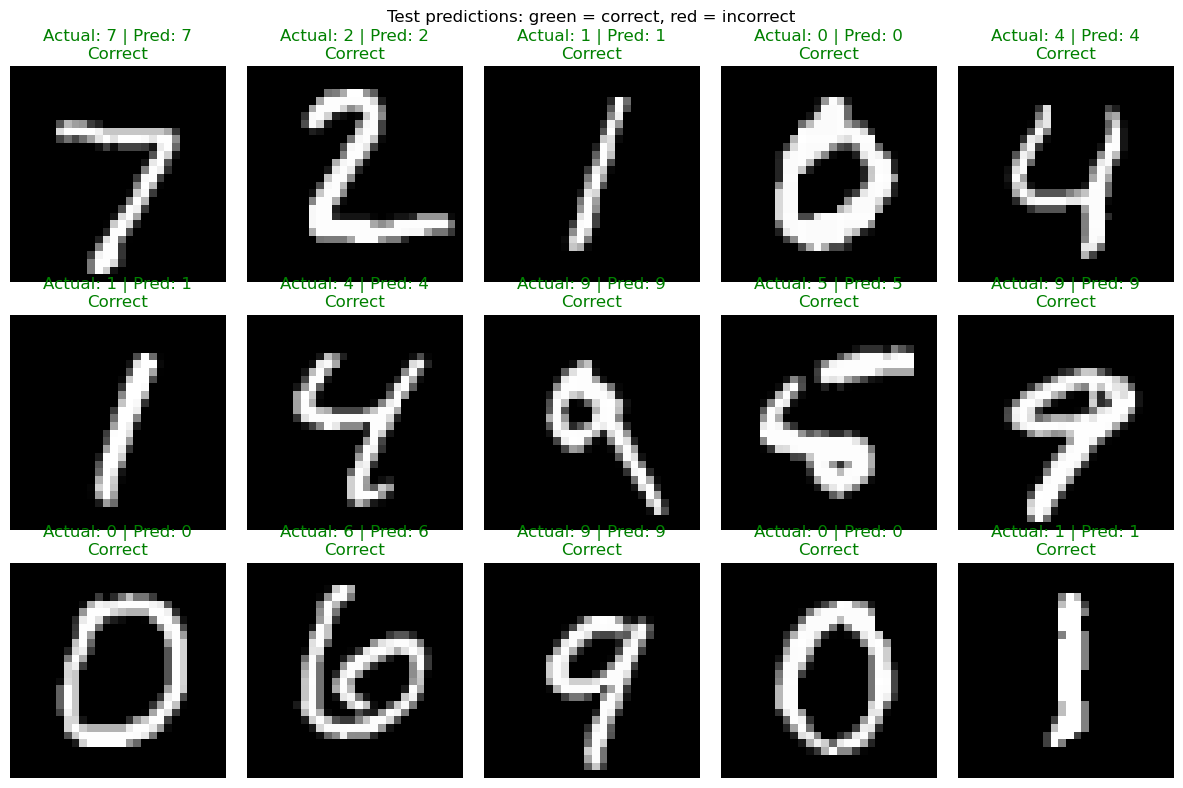

In [11]:
number_to_show = 15
fig, axes = plt.subplots(3, 5, figsize=(12, 8))
for index, axis in enumerate(axes.flat[:number_to_show]):
    is_correct = y_pred[index] == y_test[index]
    axis.imshow(x_test[index].squeeze(), cmap="gray")
    axis.set_title(
        f"Actual: {y_test[index]} | Pred: {y_pred[index]}\n"
        f"{'Correct' if is_correct else 'Incorrect'}",
        color="green" if is_correct else "red",
    )
    axis.axis("off")
fig.suptitle("Test predictions: green = correct, red = incorrect")
plt.tight_layout()
plt.show()

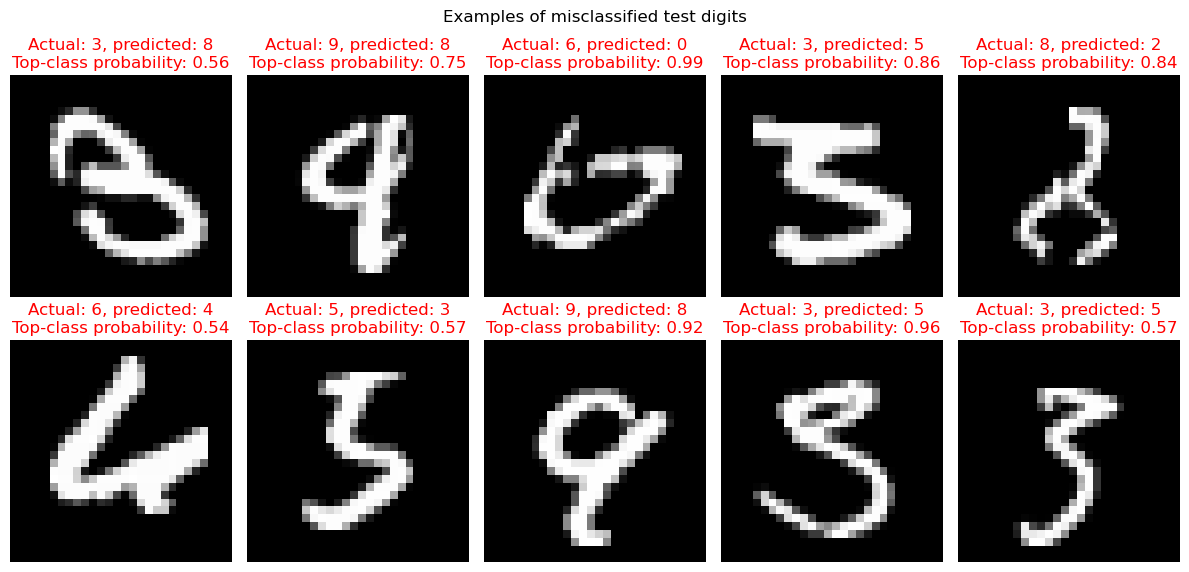

Possible reasons: some handwriting is ambiguous, unusually tilted, faint,
or shaped similarly to another digit. A small image also loses fine detail.


In [12]:
incorrect_indices = np.flatnonzero(y_pred != y_test)
if len(incorrect_indices) == 0:
    print("No incorrect predictions were found in this test run.")
else:
    count_to_show = min(10, len(incorrect_indices))
    fig, axes = plt.subplots(2, 5, figsize=(12, 6))
    for axis, index in zip(axes.flat, incorrect_indices[:count_to_show]):
        axis.imshow(x_test[index].squeeze(), cmap="gray")
        confidence = float(np.max(test_probabilities[index]))
        axis.set_title(
            f"Actual: {y_test[index]}, predicted: {y_pred[index]}\n"
            f"Top-class probability: {confidence:.2f}",
            color="red",
        )
        axis.axis("off")
    for axis in axes.flat[count_to_show:]:
        axis.axis("off")
    fig.suptitle("Examples of misclassified test digits")
    plt.tight_layout()
    plt.show()
    print("Possible reasons: some handwriting is ambiguous, unusually tilted, faint,")
    print("or shaped similarly to another digit. A small image also loses fine detail.")

### Results and discussion

Use the measured values printed in the results table and the class report in your write-up. Accuracy summarizes the overall fraction correct; precision reflects how often a predicted digit is correct; recall reflects how many examples of a digit were found; and F1 balances precision and recall. The confusion matrix reveals which pairs of digits are most often confused. The training curves help identify whether the model has converged or whether a train/validation gap suggests overfitting. Do not report a performance number until you have run this notebook.

**Strengths:** the CNN learns spatial stroke patterns directly, uses a held-out validation set and training-only augmentation, and reports per-digit as well as overall test metrics. **Limitations:** MNIST contains small, centered grayscale digits and does not represent all real-world handwriting; results can also vary slightly by software, hardware, and random operations. A confusion matrix and misclassified examples help explain errors but do not establish their cause.

In [13]:
print("Conclusion from this run")
print("-----------------------")
print(
    f"The CNN achieved {test_accuracy:.2%} test accuracy with test loss {test_loss:.4f}. "
    f"Its macro-averaged precision, recall, and F1-score were "
    f"{report['macro avg']['precision']:.4f}, {report['macro avg']['recall']:.4f}, and "
    f"{report['macro avg']['f1-score']:.4f}, respectively. These values are measured on "
    f"the untouched MNIST test set. The CNN provides a practical demonstration of "
    f"image preprocessing, convolutional feature learning, regularization, and "
    f"classification evaluation."
)

Conclusion from this run
-----------------------
The CNN achieved 99.17% test accuracy with test loss 0.0218. Its macro-averaged precision, recall, and F1-score were 0.9917, 0.9918, and 0.9917, respectively. These values are measured on the untouched MNIST test set. The CNN provides a practical demonstration of image preprocessing, convolutional feature learning, regularization, and classification evaluation.


### Limitations and possible future improvements

- Evaluate on a handwriting dataset captured from different people, writing tools, and image conditions.
- Tune augmentation strength, learning rate, batch size, and network depth using validation data only.
- Compare with a small dense network or a more carefully tuned CNN while preserving a final untouched test set.
- Add learning-rate scheduling and experiment tracking for more systematic training.
- Investigate class-specific errors and use saliency/visualization methods to understand model decisions.
- For deployment, measure latency and model size and evaluate robustness to shifts, blur, and noise.

### Project report structure

1. **Title:** Handwritten Digit Recognition Using MNIST Dataset with TensorFlow and Keras
2. **Abstract:** Briefly state the task, CNN approach, held-out evaluation method, and actual measured results.
3. **Introduction:** Explain handwritten digit classification and the use of machine learning for image recognition.
4. **Objectives:** List the goals of preprocessing, CNN training, and quantitative evaluation.
5. **Dataset Description:** Describe MNIST image size, grayscale format, digit labels, and train/test counts.
6. **Methodology:** Explain normalization, channel reshaping, stratified validation split, augmentation, and leakage prevention.
7. **Model Architecture:** Present the layer sequence, activations, optimizer, loss, metric, and callbacks.
8. **Implementation:** Describe the Python libraries, training configuration, and notebook workflow.
9. **Results and Discussion:** Include the measured metric table, learning curves, confusion matrix, and prediction/error examples.
10. **Limitations:** Discuss the simplicity and domain constraints of MNIST and the limitations of the experiment.
11. **Conclusion:** Summarize what was learned and report only the metrics from the actual run.
12. **References:** Cite the dataset and software documentation below.

### References

- LeCun, Y., Cortes, C., and Burges, C. J. C. *The MNIST Database of Handwritten Digits*. http://yann.lecun.com/exdb/mnist/
- TensorFlow. *MNIST handwritten digit classification dataset*. https://www.tensorflow.org/api_docs/python/tf/keras/datasets/mnist
- TensorFlow. *Keras Sequential model and layers documentation*. https://www.tensorflow.org/guide/keras/sequential_model
- scikit-learn. *Model evaluation: classification report and confusion matrix*. https://scikit-learn.org/stable/modules/model_evaluation.html